# Separate stress test: plants rejected during generation

All 142 unique rejected plants were recovered from the 20,000-row generation log. No model was retrained and no gain predictions were clipped. The accepted dataset and main test results are unchanged.

This set is **rejection-biased**, not a random final test set. There are no accepted optimized target gains for these plants, so gain errors and optimal-target ITAE ratios cannot be reported.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "report_rejected_plants.py").exists())
sys.path.insert(0, str(root / "scripts"))
sys.path.insert(0, str(root / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from report_rejected_plants import load, success_plot, outcome_plot, example_ids, response_plot, OUT
from plot_baselines import style
style()
stress, plants, summary = load()
protocol = json.loads((OUT / "protocol.json").read_text())
display(plants.original_reason.value_counts().rename("Rejected plants"))
display(summary)

original_reason
resolution_limit              102
overshoot                      36
overshoot+resolution_limit      4
Name: Rejected plants, dtype: int64

,plants,strict_passes,stable,extended_attempts,passes_with_extended_budget
model,,,,,
linear,142,5,130,93,58
ridge,142,5,128,93,58
polynomial_ridge,142,16,141,95,79
random_forest,142,19,142,106,101
xgboost,142,28,142,106,111
standard_mlp,142,34,142,106,118


## Original budget versus a larger sampling budget

Strict validation uses the unchanged original 65,537-point cap. Only predictions that fail with `resolution_limit` are retried with up to 262,145 points. All thresholds, gain bounds, stability checks, tail/error convergence tolerances and the 1,000-second horizon limit remain unchanged.

The secondary policy retains strict passes and other strict failures; it retries only sampling-limit cases. It is reported separately, rather than silently replacing the main validation protocol. A resource-limit result is **unresolved**, not proof of instability or lack of a feasible controller.

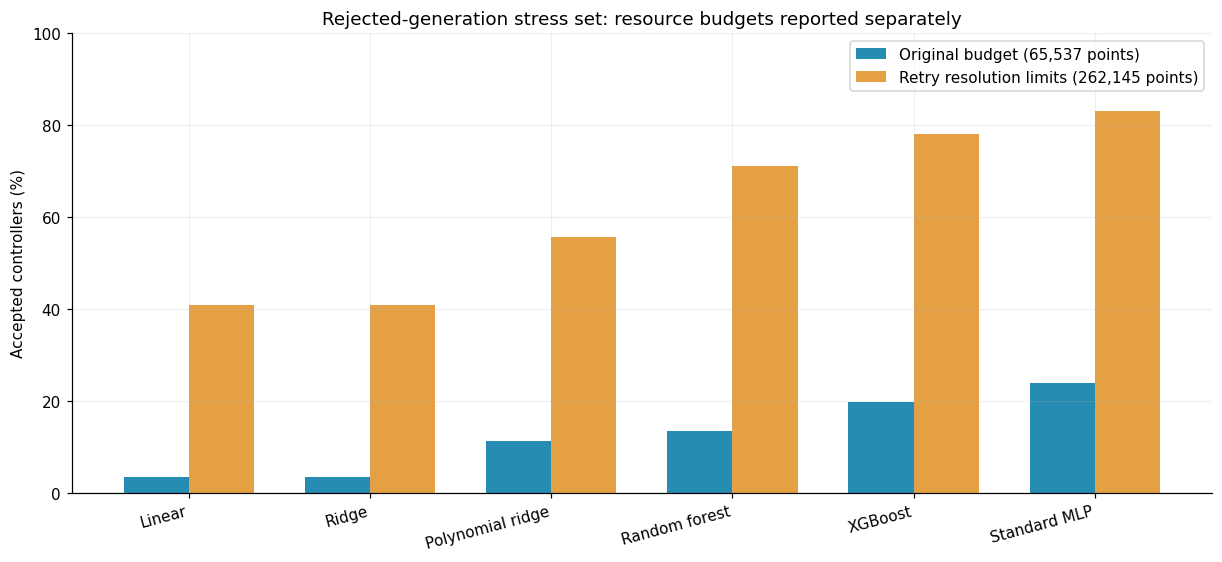

In [2]:
fig = success_plot(summary)
plt.show()

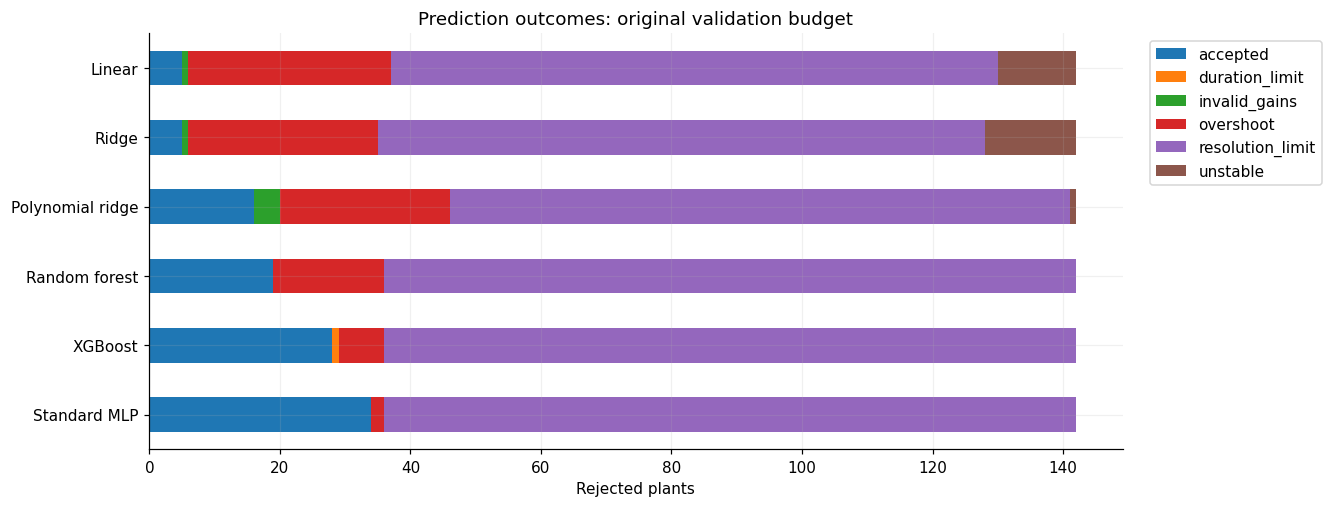

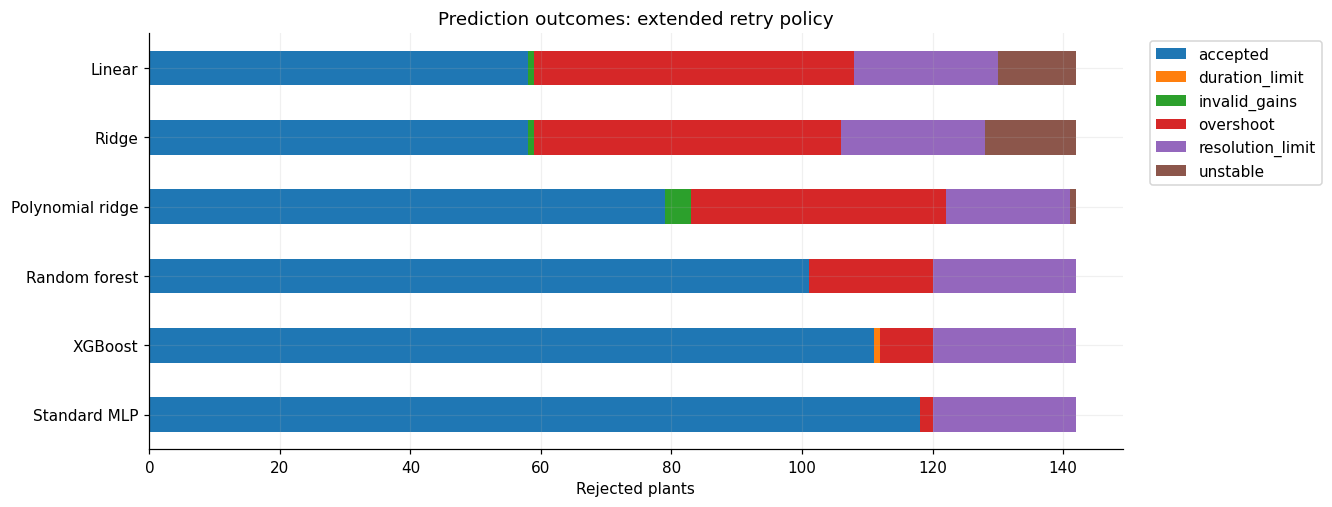

In [3]:
fig = outcome_plot(stress)
plt.show()
fig = outcome_plot(stress, extended=True)
plt.show()

## Results by original rejection reason

Reason dictionaries in the original log count individual optimizer starts. At plant level, there are 102 resolution-only, 36 overshoot-only and four mixed-reason plants. Earlier shorthand based on dividing start-level totals by four did not account for mixed plants.

In [4]:
display(pd.read_csv(OUT / "by_original_rejection.csv"))

,model,original_reason,plants,strict_passes,passes_with_extended_budget
0,linear,resolution_limit,102,4,57
1,linear,overshoot,36,1,1
2,linear,overshoot+resolution_limit,4,0,0
3,ridge,resolution_limit,102,4,57
4,ridge,overshoot,36,1,1
5,ridge,overshoot+resolution_limit,4,0,0
6,polynomial_ridge,resolution_limit,102,3,63
7,polynomial_ridge,overshoot,36,12,13
8,polynomial_ridge,overshoot+resolution_limit,4,1,3
9,random_forest,resolution_limit,102,2,78


## Absolute performance for validated predictions

These are **absolute** ITAE and J measurements on the passing subset. Passing subsets differ across models; comparing medians alone can mislead. There is no optimized reference controller for these rejected plants. Missing metrics are not zero. Rejected-controller plots and finite-window peaks are not substitutes for validation.

In [5]:
costs = []
for name, group in stress.groupby("model", sort=False):
    accepted = group[group.extended_accepted]
    costs.append({"model": name, "validated_controllers": len(accepted),
                  "median_validated_ITAE": accepted.extended_itae.median(),
                  "median_validated_J": accepted.extended_objective.median(),
                  "max_validated_overshoot_pct": accepted.extended_overshoot_pct.max()})
display(pd.DataFrame(costs).round(4))

,model,validated_controllers,median_validated_ITAE,median_validated_J,max_validated_overshoot_pct
0,linear,58,0.1525,1.3339,8.3616
1,ridge,58,0.1525,1.3333,8.9793
2,polynomial_ridge,79,0.1431,1.0762,9.8062
3,random_forest,101,0.0629,0.6140,9.9895
4,xgboost,111,0.0868,0.6838,9.8269
5,standard_mlp,118,0.0774,0.6414,8.8073


## Illustrative predicted responses

These four examples are selected transparently using the MLP outcomes: a strict pass, a larger-budget-only pass, a remaining overshoot failure, and an unresolved sampling limit. Every model is shown on the same plant. There is no optimized-target curve.

The plotted horizon and 4,001 display points are for illustration only. A plausible-looking curve does not prove resolved peaks/ITAE; follow the saved validator verdict. Divergent responses may exceed the displayed output range.

In [6]:
examples = example_ids(stress)
display(pd.Series(examples, name="Rejected-plant ID"))

Passes original budget         3
Passes only larger budget      0
Overshoot failure            114
Unresolved sampling limit      4
Name: Rejected-plant ID, dtype: int64

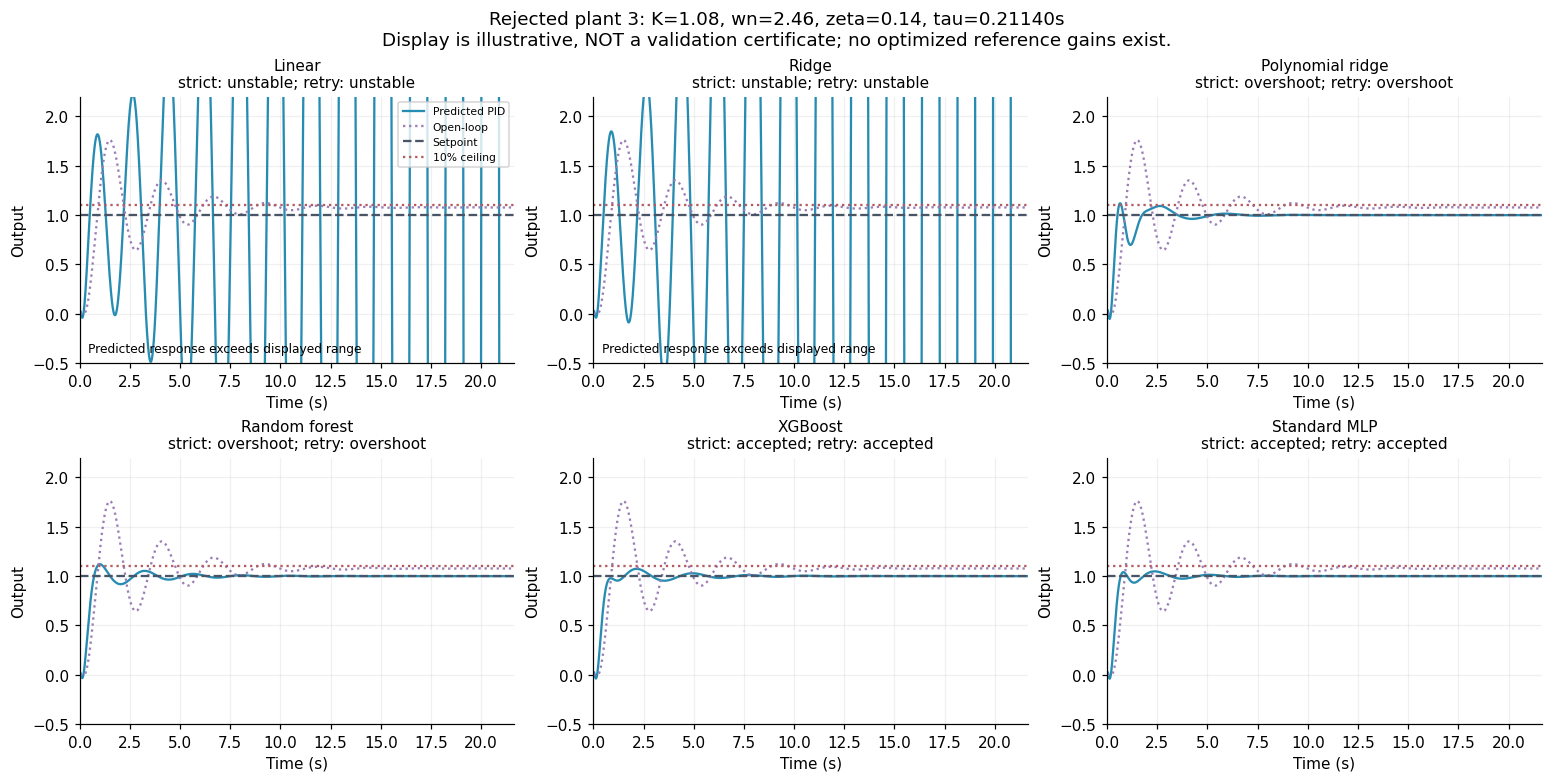

In [7]:
fig = response_plot(stress, examples['Passes original budget'])
plt.show()

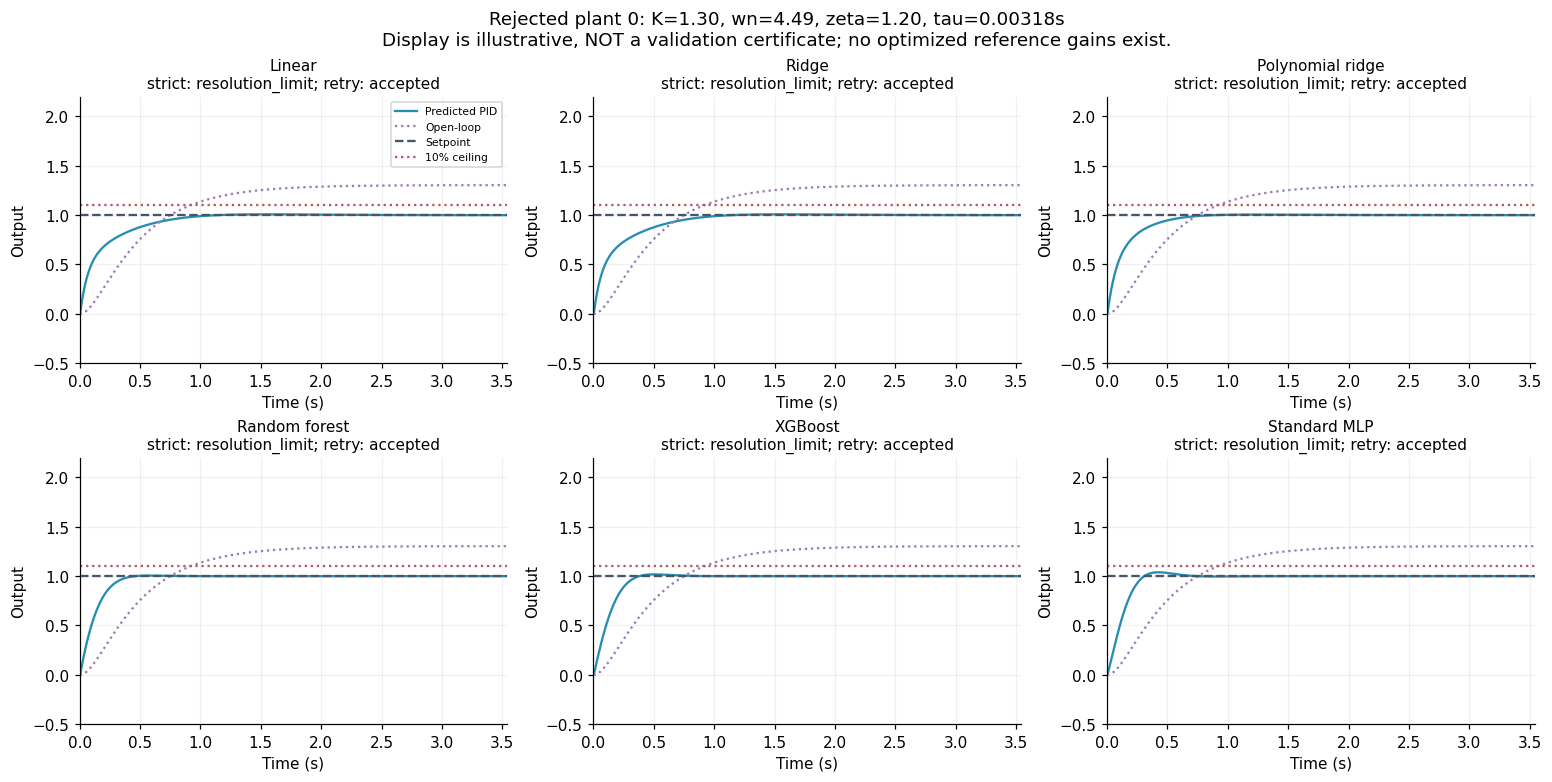

In [8]:
fig = response_plot(stress, examples['Passes only larger budget'])
plt.show()

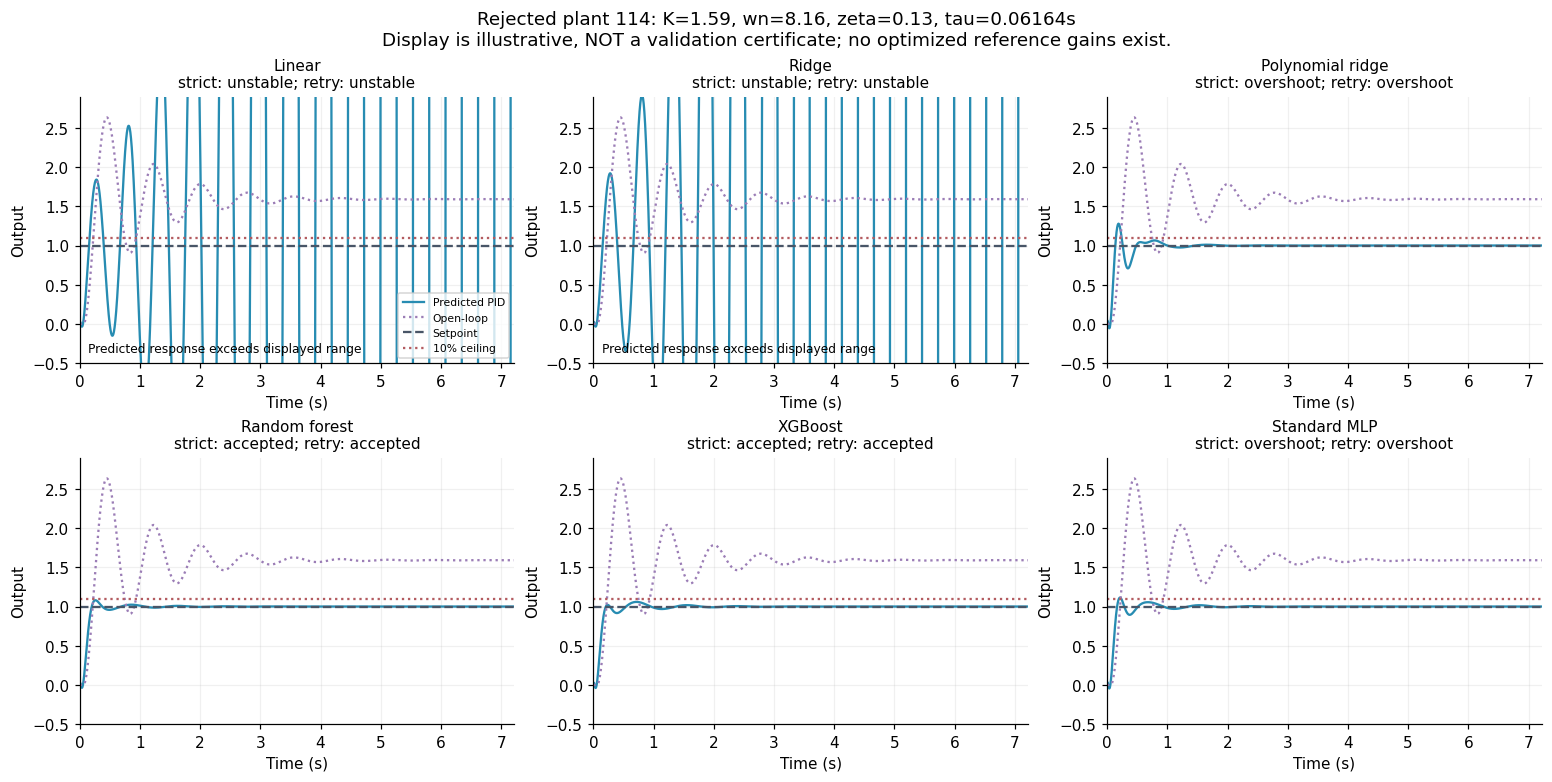

In [9]:
fig = response_plot(stress, examples['Overshoot failure'])
plt.show()

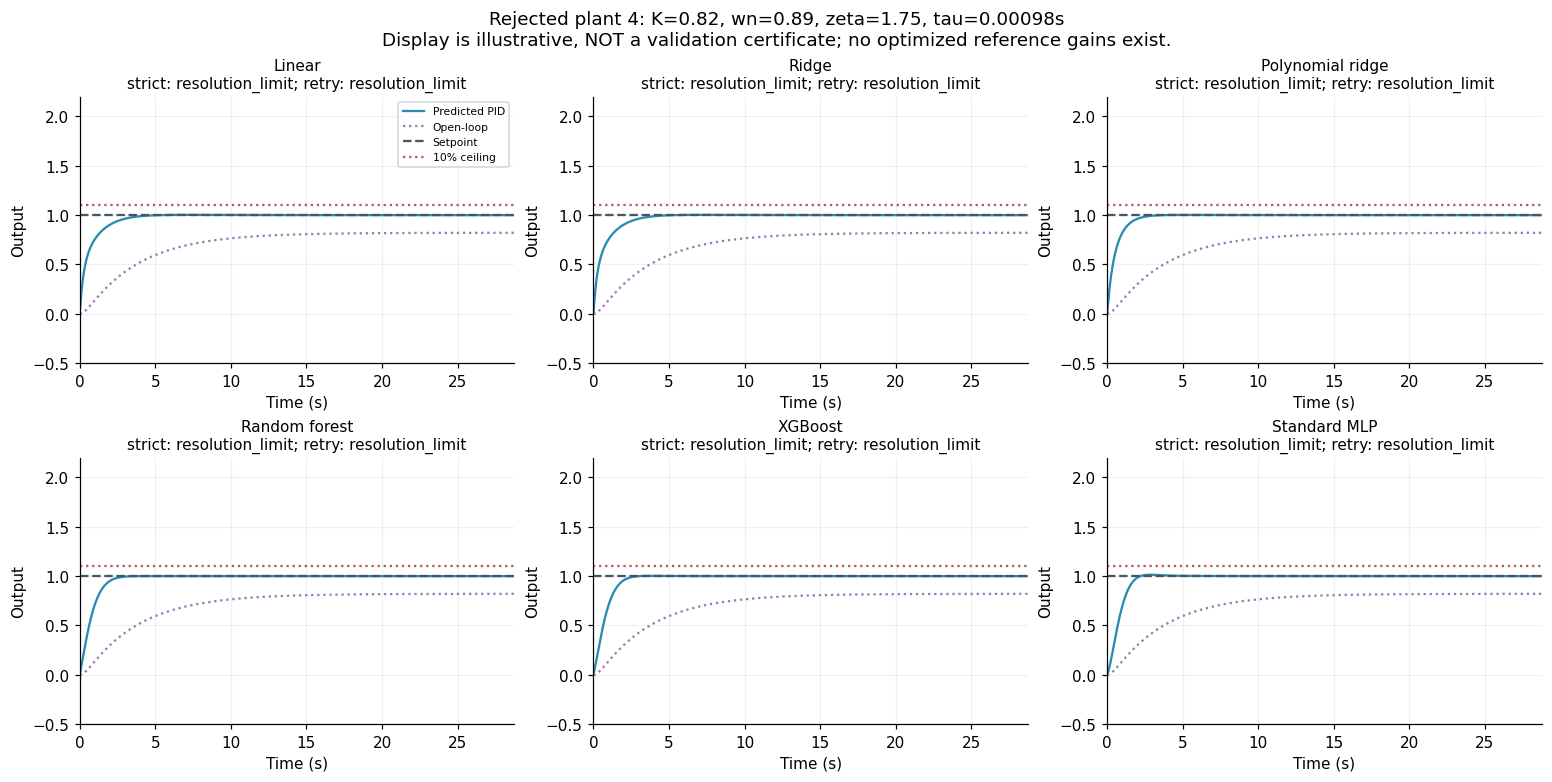

In [10]:
fig = response_plot(stress, examples['Unresolved sampling limit'])
plt.show()

## Repeat validation of the four MLP examples

This reuses frozen predicted gains and the same strict/secondary-budget logic. No optimization, model fitting or tolerance changes occur.

In [11]:
from stress_rejected_plants import validate
checks = []
for description, plant_id in examples.items():
    row = stress[(stress.model == "standard_mlp") & (stress.rejection_id == plant_id)].iloc[0]
    task = ("standard_mlp", int(plant_id), [row.zeta, row.wn, row.tau, row.K],
            [row.predicted_Kp, row.predicted_Ki, row.predicted_Kd], protocol["gain_penalty"])
    result = validate(task)
    checks.append({"example": description, "strict_reason": result["reason"],
                   "extended_reason": result["extended_reason"],
                   "matches_saved": result["reason"] == row.reason and result["extended_reason"] == row.extended_reason})
display(pd.DataFrame(checks))
print("Matching saved outcomes:", sum(c["matches_saved"] for c in checks), "/", len(checks))

,example,strict_reason,extended_reason,matches_saved
0,Passes original budget,accepted,accepted,True
1,Passes only larger budget,resolution_limit,accepted,True
2,Overshoot failure,overshoot,overshoot,True
3,Unresolved sampling limit,resolution_limit,resolution_limit,True


Matching saved outcomes: 4 / 4


## Interpretation

ML can propose validated gains for plants rejected by the labeling pipeline. Rejection does not mean PID control is impossible. The MLP passes 34/142 under the original budget and 118/142 with the secondary budget policy; all 142 predictions are pole-stable. Two still fail overshoot and 22 remain sampling-limited after the retry.

These results should not be pooled with the main accepted-data test score. They expose a numerical resource/coverage limitation, especially around very small positive delays and stiff Padé dynamics. The model is not proven optimal or physically safe. Full results are at `results/rejected_plants/report.md`.

Reproduce with `python scripts/stress_rejected_plants.py`, then `python scripts/report_rejected_plants.py`. This notebook reads saved predictions; only the final four-example check reruns simulations.